In [4]:
pip install requests_cache retry_requests

  Attempting uninstall: typing-extensions
    Found existing installation: typing_extensions 4.13.2
    Uninstalling typing_extensions-4.13.2:
      Successfully uninstalled typing_extensions-4.13.2
  Attempting uninstall: attrs
    Found existing installation: attrs 25.3.0
    Uninstalling attrs-25.3.0:
      Successfully uninstalled attrs-25.3.0
Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow-intel 2.18.0 requires numpy<2.1.0,>=1.26.0, but you have numpy 2.3.2 which is incompatible.

[notice] A new release of pip is available: 25.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import openmeteo_requests
import requests_cache
from retry_requests import retry
import warnings

warnings.filterwarnings('ignore')

# Setup clean visual aesthetics for your manager's report
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_context("notebook", font_scale=1.1)

In [7]:
# 1. Load the interim dataset containing the DAY-AHEAD weather forecasts
df = pd.read_csv("../data/interim/features_all_systems.csv")
df['timestamp'] = pd.to_datetime(df['timestamp'], utc=True)

# 2. Load the shortlisted metadata to get exact house coordinates
meta_df = pd.read_csv("../data/interim/pvoutput_selection/shortlist.csv")
system_coords = meta_df[['system_id', 'latitude', 'longitude']].drop_duplicates()

# 3. Extract temporal metadata for our plots
df['date'] = df['timestamp'].dt.date
df['hour'] = df['timestamp'].dt.hour
df['month'] = df['timestamp'].dt.month

# 4. Map months to meteorological seasons
season_map = {12: 'Winter', 1: 'Winter', 2: 'Winter',
              3: 'Spring', 4: 'Spring', 5: 'Spring',
              6: 'Summer', 7: 'Summer', 8: 'Summer',
              9: 'Autumn', 10: 'Autumn', 11: 'Autumn'}
df['season'] = df['month'].map(season_map)

print(f"Loaded {len(df):,} forecast rows.")
print(f"Loaded coordinates for {len(system_coords)} distinct solar systems.")

Loaded 2,581,824 forecast rows.
Loaded coordinates for 35 distinct solar systems.


In [8]:
# Setup Open-Meteo API client with caching
cache_session = requests_cache.CachedSession('.cache', expire_after=-1)
retry_session = retry(cache_session, retries=5, backoff_factor=0.2)
openmeteo = openmeteo_requests.Client(session=retry_session)

start_date = df['timestamp'].min().strftime('%Y-%m-%d')
end_date = df['timestamp'].max().strftime('%Y-%m-%d')

# Extract coordinate lists directly from the metadata dataframe
lats = system_coords['latitude'].tolist()
lons = system_coords['longitude'].tolist()

print(f"Fetching ERA5 Ground Truth Weather for {len(lats)} locations from {start_date} to {end_date}...")

# Call Open-Meteo Historical Archive (ERA5)
url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": lats,
    "longitude": lons,
    "start_date": start_date,
    "end_date": end_date,
    "hourly": ["shortwave_radiation", "cloud_cover"],
    "timezone": "UTC"
}

# The API client returns a list of results when multiple coordinates are supplied
responses = openmeteo.weather_api(url, params=params)

truth_dfs = []

# Loop through each response and attach the corresponding system_id
for i, response in enumerate(responses):
    # Match the response back to the system_id using the index
    sys_id = system_coords.iloc[i]['system_id']
    
    hourly = response.Hourly()
    dt_range = pd.date_range(
        start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
        end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
        freq=pd.Timedelta(seconds=hourly.Interval()),
        inclusive="left"
    )
    
    temp_df = pd.DataFrame({
        "system_id": sys_id,
        "timestamp": dt_range,
        "actual_ghi": hourly.Variables(0).ValuesAsNumpy(),
        "actual_cloud": hourly.Variables(1).ValuesAsNumpy()
    })
    truth_dfs.append(temp_df)

# Combine all individual house dataframes into one master ground truth dataframe
truth_df = pd.concat(truth_dfs, ignore_index=True)
print("Successfully fetched and combined actual historical weather for all systems!")

Fetching ERA5 Ground Truth Weather for 35 locations from 2024-03-31 to 2026-05-31...
Successfully fetched and combined actual historical weather for all systems!


In [10]:
# 1. Enforce matching data types for the 'by' key (system_id)
df['system_id'] = df['system_id'].astype(int)
truth_df['system_id'] = truth_df['system_id'].astype(int)

# 2. Ensure timestamps are in the same datetime format (UTC)
df['timestamp'] = pd.to_datetime(df['timestamp'], utc=True)
truth_df['timestamp'] = pd.to_datetime(truth_df['timestamp'], utc=True)

# 3. Sort both datasets by timestamp (required by pd.merge_asof)
df = df.sort_values('timestamp').reset_index(drop=True)
truth_df = truth_df.sort_values('timestamp').reset_index(drop=True)

# 4. Perform the asof merge
merged_df = pd.merge_asof(
    df, 
    truth_df, 
    on='timestamp', 
    by='system_id',
    direction='nearest'
)

# 5. Define the columns to compare
fc_ghi_col = 'clearsky_ghi'   # Replace with your forecast GHI column (e.g. 'ghi_fc' or 'poa_global_fc')
fc_cloud_col = 'cloud_fc2'    # Replace with your forecast cloud cover column

# 6. Calculate the absolute errors
merged_df['ghi_error'] = np.abs(merged_df['actual_ghi'] - merged_df[fc_ghi_col])
merged_df['cloud_error'] = np.abs(merged_df['actual_cloud'] - merged_df[fc_cloud_col])

# 7. Filter for daylight slots (GHI > 10 W/m²)
daylight_df = merged_df[merged_df['actual_ghi'] > 10].copy()

print(f"Successfully merged {len(daylight_df):,} daylight slots across {daylight_df['system_id'].nunique()} systems.")

Successfully merged 1,199,336 daylight slots across 32 systems.


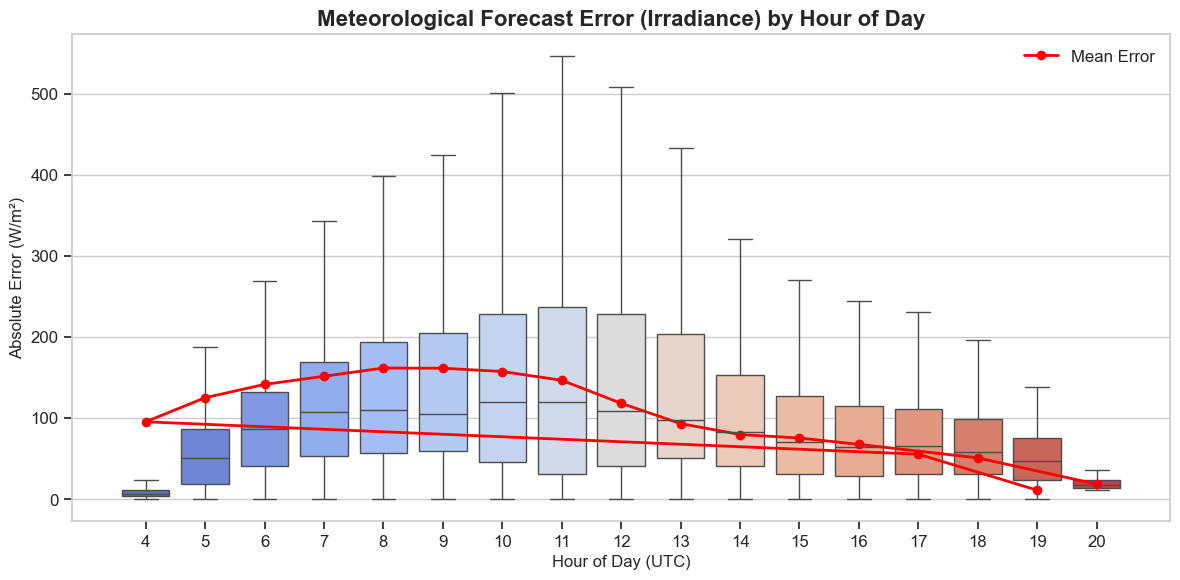

In [11]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=daylight_df, x='hour', y='ghi_error', showfliers=False, palette='coolwarm')

plt.title('Meteorological Forecast Error (Irradiance) by Hour of Day', fontsize=16, fontweight='bold')
plt.xlabel('Hour of Day (UTC)', fontsize=12)
plt.ylabel('Absolute Error (W/m²)', fontsize=12)

# Overlay the mean error trendline
mean_by_hour = daylight_df.groupby('hour')['ghi_error'].mean()
plt.plot(
    mean_by_hour.index.map(lambda x: list(daylight_df['hour'].unique()).index(x)), 
    mean_by_hour.values, color='red', marker='o', linewidth=2, label='Mean Error'
)

plt.legend()
plt.tight_layout()
plt.show()

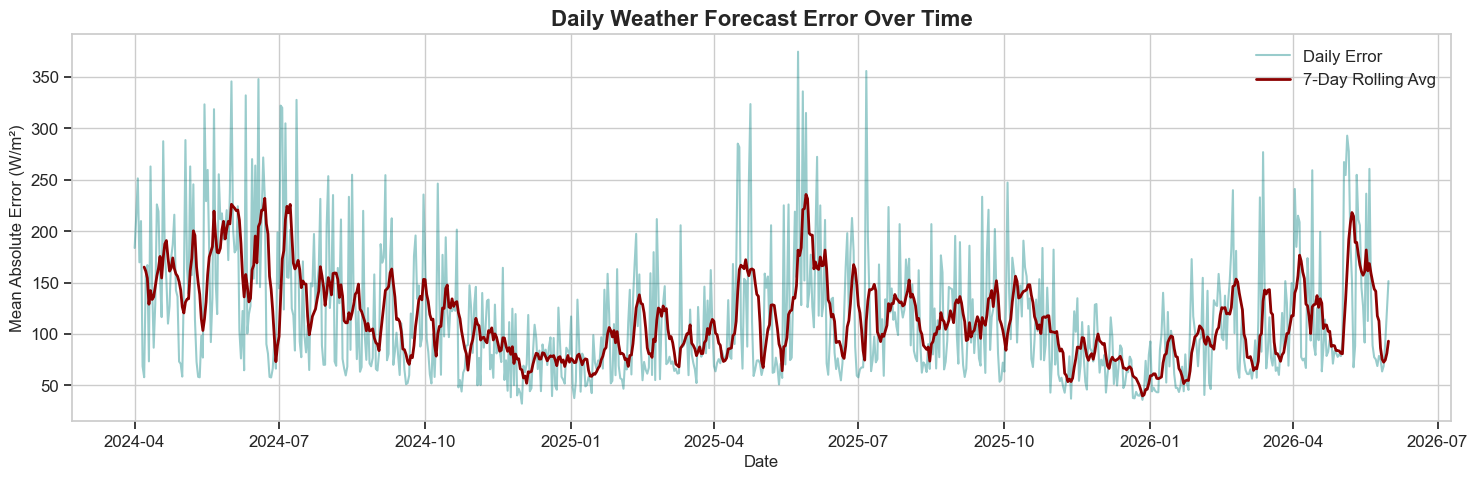

In [12]:
daily_error = daylight_df.groupby('date')['ghi_error'].mean().reset_index()
daily_error['date'] = pd.to_datetime(daily_error['date'])

plt.figure(figsize=(15, 5))
plt.plot(daily_error['date'], daily_error['ghi_error'], alpha=0.4, color='teal', label='Daily Error')

# 7-day rolling average to identify high-error weather fronts or weeks
plt.plot(
    daily_error['date'], daily_error['ghi_error'].rolling(7).mean(), 
    color='darkred', linewidth=2, label='7-Day Rolling Avg'
)

plt.title('Daily Weather Forecast Error Over Time', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Mean Absolute Error (W/m²)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

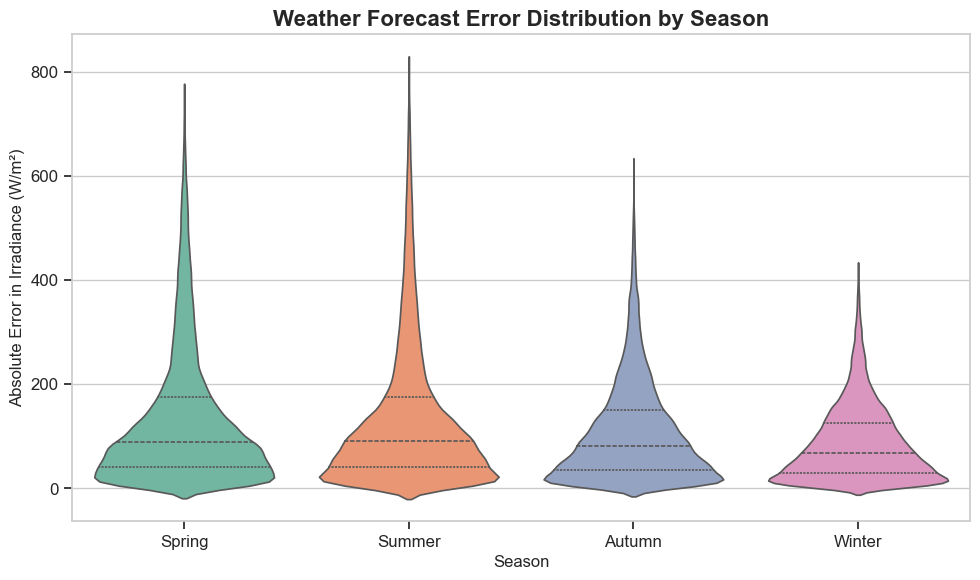

In [13]:
plt.figure(figsize=(10, 6))
sns.violinplot(
    data=daylight_df, x='season', y='ghi_error', 
    order=['Spring', 'Summer', 'Autumn', 'Winter'], 
    palette='Set2', inner='quartile'
)

plt.title('Weather Forecast Error Distribution by Season', fontsize=16, fontweight='bold')
plt.xlabel('Season', fontsize=12)
plt.ylabel('Absolute Error in Irradiance (W/m²)', fontsize=12)
plt.tight_layout()
plt.show()

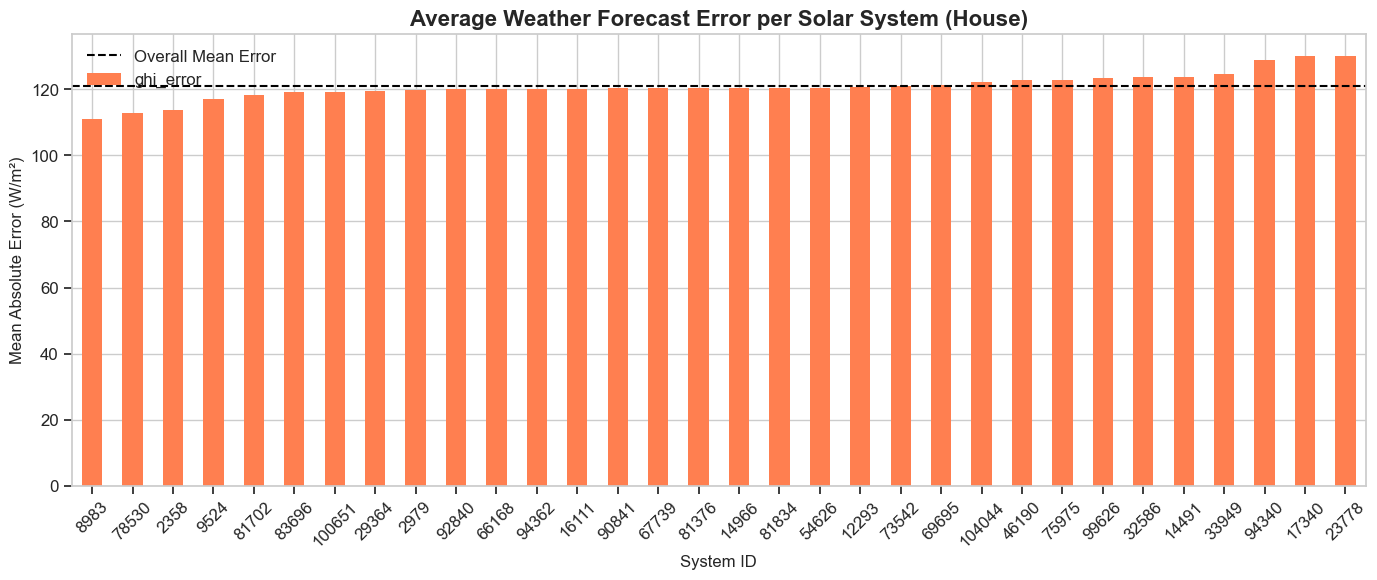

In [14]:
system_error = daylight_df.groupby('system_id')['ghi_error'].mean().sort_values()

plt.figure(figsize=(14, 6))
system_error.plot(kind='bar', color='coral')

plt.title('Average Weather Forecast Error per Solar System (House)', fontsize=16, fontweight='bold')
plt.xlabel('System ID', fontsize=12)
plt.ylabel('Mean Absolute Error (W/m²)', fontsize=12)
plt.xticks(rotation=45)

# Overall mean line
plt.axhline(daylight_df['ghi_error'].mean(), color='black', linestyle='--', label='Overall Mean Error')
plt.legend()
plt.tight_layout()
plt.show()

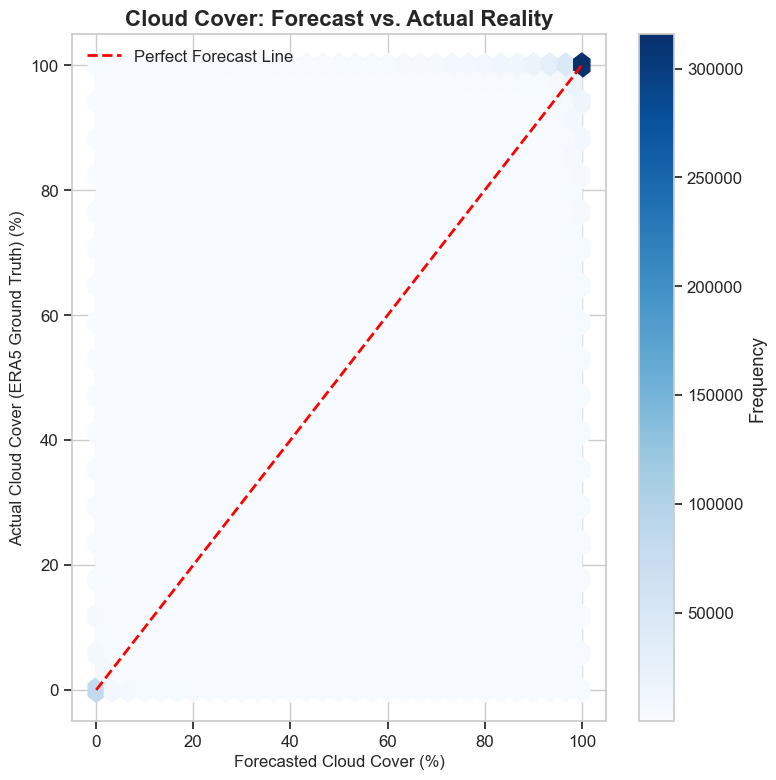

In [15]:
plt.figure(figsize=(8, 8))

# Hexbin plot handles massive densities of scatter points perfectly
plt.hexbin(
    daylight_df[fc_cloud_col], daylight_df['actual_cloud'], 
    gridsize=30, cmap='Blues', mincnt=1
)

# Perfect prediction line
plt.plot([0, 100], [0, 100], color='red', linestyle='--', linewidth=2, label='Perfect Forecast Line')

cb = plt.colorbar(label='Frequency')
plt.title('Cloud Cover: Forecast vs. Actual Reality', fontsize=16, fontweight='bold')
plt.xlabel('Forecasted Cloud Cover (%)', fontsize=12)
plt.ylabel('Actual Cloud Cover (ERA5 Ground Truth) (%)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

Initiating robust multi-model forecast fetch for comparison...
Fetching ECMWF (Europe)...
  -> Success! MAE: 27.95 W/m² (Found 9383 valid daylight hours)
Fetching ICON (Germany)...
  -> Success! MAE: 49.18 W/m² (Found 9383 valid daylight hours)
Fetching GFS (USA)...
  -> Success! MAE: 65.55 W/m² (Found 9383 valid daylight hours)


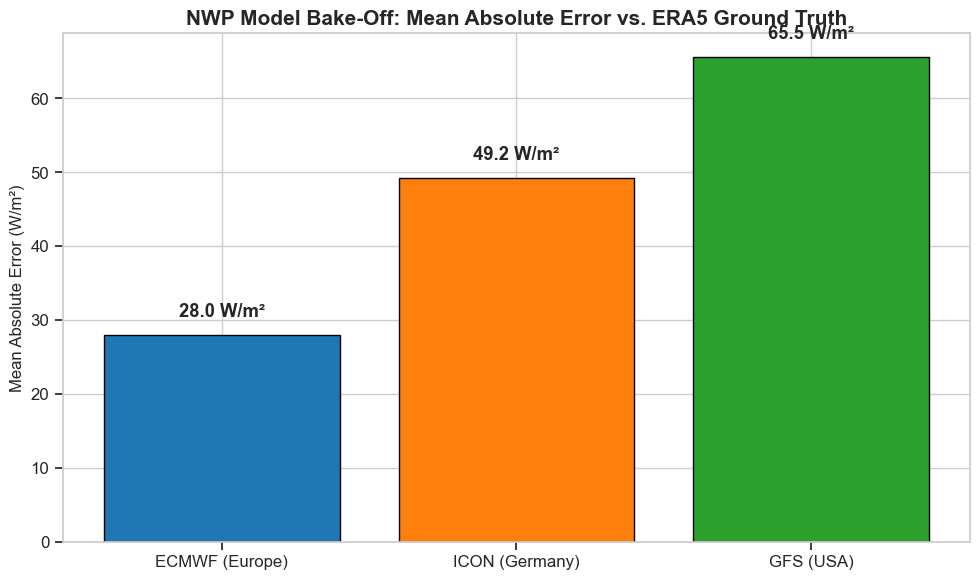

In [20]:
# -------------------------------------------------------------------
# THE NWP BAKE-OFF: ECMWF vs. ICON (DWD) vs. GFS (Robust Version)
# -------------------------------------------------------------------
print("Initiating robust multi-model forecast fetch for comparison...")

# Open-Meteo's Historical Forecast endpoint
forecast_url = "https://historical-forecast-api.open-meteo.com/v1/forecast"

# Dictionary of models to test
nwp_models = {
    "ECMWF (Europe)": "ecmwf_ifs025", 
    "ICON (Germany)": "icon_seamless", 
    "GFS (USA)": "gfs_seamless"
}

# We will just use the first house's coordinates for a quick benchmark
test_lat = system_coords.iloc[0]['latitude']
test_lon = system_coords.iloc[0]['longitude']

# Isolate the ERA5 ground truth for this specific house and daylight hours only
truth_test_house = truth_df[truth_df['system_id'] == system_coords.iloc[0]['system_id']].copy()
truth_test_house = truth_test_house[truth_test_house['actual_ghi'] > 10].sort_values('timestamp')

errors = {}

# Loop through each model and make a separate, safe request
for model_name, model_code in nwp_models.items():
    try:
        print(f"Fetching {model_name}...")
        params = {
            "latitude": test_lat,
            "longitude": test_lon,
            "start_date": start_date,
            "end_date": end_date,
            "hourly": ["shortwave_radiation"],
            "models": model_code,
            "timezone": "UTC"
        }
        
        response = openmeteo.weather_api(forecast_url, params=params)[0]
        hourly = response.Hourly()
        
        dt_range = pd.date_range(
            start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
            end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
            freq=pd.Timedelta(seconds=hourly.Interval()),
            inclusive="left"
        )
        
        # Create temporary dataframe for this specific NWP model
        temp_df = pd.DataFrame({
            "timestamp": dt_range,
            "fc_ghi": hourly.Variables(0).ValuesAsNumpy()
        }).sort_values('timestamp')
        
        # Merge safely with ground truth
        merged = pd.merge_asof(
            truth_test_house,
            temp_df,
            on='timestamp',
            direction='nearest'
        ).dropna()
        
        # Calculate Mean Absolute Error
        # Calculate Mean Absolute Error (ignoring missing gaps)
        # Calculate Mean Absolute Error
        mae = np.abs(merged['actual_ghi'] - merged['fc_ghi']).dropna().mean()
        valid_rows = merged['fc_ghi'].notna().sum()
        
        errors[model_name] = mae
        print(f"  -> Success! MAE: {mae:.2f} W/m² (Found {valid_rows} valid daylight hours)")
        
    except Exception as e:
        print(f"  -> Failed to process {model_name}. It may lack data for this date range.")

# Plot the Results (if we successfully fetched at least one model)
if errors:
    plt.figure(figsize=(10, 6))
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c'][:len(errors)]
    bars = plt.bar(errors.keys(), errors.values(), color=colors, edgecolor='black')

    plt.title('NWP Model Bake-Off: Mean Absolute Error vs. ERA5 Ground Truth', fontsize=15, fontweight='bold')
    plt.ylabel('Mean Absolute Error (W/m²)', fontsize=12)

    # Add the exact values on top of the bars
    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, yval + 2, f'{yval:.1f} W/m²', ha='center', va='bottom', fontweight='bold')

    plt.tight_layout()
    plt.show()
else:
    print("No models returned data successfully. Check your date range or coordinate variables.")